## EDA and Modeling
This notebook contains the exploratory data analysis and machine learning development for the player market value model.
The modeling dataset was constructed in SQL and contains one observation per player and season, combining player characteristics, season performance, club context, transfer history and historical market valuation information.
The objective of the analysis is to understand the final modeling dataset, define the appropriate preprocessing strategy and develop regression models to estimate end-of-season player market value.

### 1. Setup and Imports

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv("../data/processed/modeling_dataset_v1.csv")

### 2. Basic EDA

In [3]:
df.shape

(15357, 42)

In [4]:
df.head()

,season,player_id,name,player_code,age_at_valuation,position,sub_position,foot,height_in_cm,total_games_played_season,total_minutes_played,total_goals,goals_per_90_min,total_assists,assists_per_90_min,goal_contributions_per_90_min,total_yellow_cards,yellow_cards_per_90_min,total_red_cards,red_cards_per_90_min,total_clean_sheets,clean_sheet_rate,primary_club_id,competition_id,clubs_played_for_season,club_goals_scored,club_goals_conceded,wins,draws,losses,club_games_played,points,avg_points_per_game,player_game_participation_rate,previous_market_value_in_eur,days_since_previous_valuation,total_previous_transfers,transfers_during_season,has_previous_transfer,days_since_last_transfer,valuation_date,target_market_value_in_eur
0,2020,3333,James Milner,james-milner,35.0,Midfield,Central Midfield,right,175.0,26,1061,0,0.000,1,0.085,0.085,3,0.25448,0,0.00000,9,0.346,31,GB1,1,68,42,20,9,9,38,69,1.82,0.684,3000000.0,82.0,10,0,1,2169.0,2021-06-08,3000000
1,2020,3455,Zlatan Ibrahimović,zlatan-ibrahimović,39.0,Attack,Centre-Forward,right,195.0,19,1497,15,0.902,2,0.120,1.022,2,0.12024,1,0.06012,6,0.316,5,IT1,1,74,41,24,7,7,38,79,2.08,0.500,5000000.0,156.0,0,0,0,NaN,2021-06-03,4000000
2,2020,4357,Klaas-Jan Huntelaar,klaas-jan-huntelaar,37.0,Attack,Centre-Forward,right,186.0,9,591,2,NaN,1,NaN,NaN,2,NaN,0,NaN,1,NaN,33,L1,1,25,86,3,7,24,34,16,0.47,0.265,800000.0,119.0,0,0,0,NaN,2021-06-09,800000
3,2020,4811,Hilton,hilton,43.0,Defender,Centre-Back,right,180.0,29,2114,0,0.000,1,0.043,0.043,4,0.17029,2,0.08515,3,0.103,969,FR1,1,60,62,14,12,12,38,54,1.42,0.763,100000.0,232.0,0,0,0,NaN,2021-06-04,150000
4,2020,5017,Niklas Moisander,niklas-moisander,35.0,Defender,Centre-Back,left,183.0,18,1218,0,0.000,0,0.000,0.000,3,0.22167,0,0.00000,3,0.167,86,L1,1,36,57,7,10,17,34,31,0.91,0.529,700000.0,119.0,0,0,0,NaN,2021-06-09,700000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15357 entries, 0 to 15356
Data columns (total 42 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   season                          15357 non-null  int64  
 1   player_id                       15357 non-null  int64  
 2   name                            15357 non-null  object 
 3   player_code                     15357 non-null  object 
 4   age_at_valuation                15354 non-null  float64
 5   position                        15357 non-null  object 
 6   sub_position                    15356 non-null  object 
 7   foot                            15296 non-null  object 
 8   height_in_cm                    15321 non-null  float64
 9   total_games_played_season       15357 non-null  int64  
 10  total_minutes_played            15357 non-null  int64  
 11  total_goals                     15357 non-null  int64  
 12  goals_per_90_min                

### 3. Main Dataset Findings
Please refer to section `7.Report Dataset Construction` on `report.md` for the full investigation performed. Including below only the main findings.

In [6]:
# Duplicated players and seasons
print(
    "Duplicated player-seasons:",
    df.duplicated(subset=["player_id", "season"]).sum()
)

# Size per season
df.groupby("season").size()

Duplicated player-seasons: 0


season
2020    2617
2021    2485
2022    2657
2023    2650
2024    2489
2025    2459
dtype: int64

In [7]:
# Missing values check in key cols
key_columns = [
    "age_at_valuation",
    "position",
    "sub_position",
    "foot",
    "height_in_cm",
    "previous_market_value_in_eur",
    "days_since_last_transfer",
    "target_market_value_in_eur"
]

df[key_columns].isna().sum()

age_at_valuation                   3
position                           0
sub_position                       1
foot                              61
height_in_cm                      36
previous_market_value_in_eur      82
days_since_last_transfer        1452
target_market_value_in_eur         0
dtype: int64

### 4. Target Variable Analysis
The target variable is target_market_value_in_eur, representing the player's end-of-season market value.

Before training any model, the distribution of the target should be analysed to understand its scale, skewness and the presence of extreme values. Football market values are expected to be highly unequal, with a large number of lower-valued players and a relatively small number of very high-valued players.

##### 4.1 Basic Statistics

In [8]:
# Describe target variable
target = "target_market_value_in_eur"

df[target].describe()

count    1.535700e+04
mean     1.123860e+07
std      1.681029e+07
min      2.500000e+04
25%      1.800000e+06
50%      5.000000e+06
75%      1.500000e+07
max      2.000000e+08
Name: target_market_value_in_eur, dtype: float64

In [9]:
# Clean useful prints
print(f"Median: €{df[target].median():,.0f}")
print(f"Mean:   €{df[target].mean():,.0f}")
print(f"Min:    €{df[target].min():,.0f}")
print(f"Max:    €{df[target].max():,.0f}")

Median: €5,000,000
Mean:   €11,238,598
Min:    €25,000
Max:    €200,000,000


#### 4.2 Raw Target Distribution Visualization

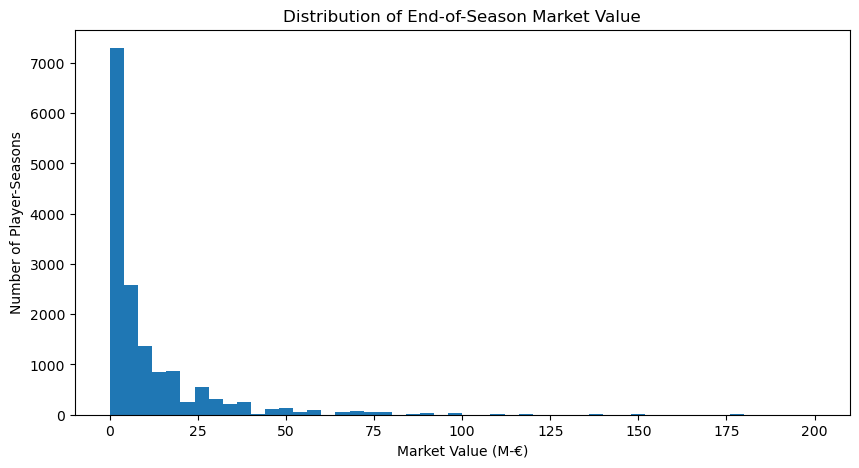

In [10]:
# Raw target distribution
plt.figure(figsize=(10, 5))

plt.hist(df[target] / 1_000_000, bins=50)

plt.title("Distribution of End-of-Season Market Value")
plt.xlabel("Market Value (M-€)")
plt.ylabel("Number of Player-Seasons")

plt.show()

In [11]:
# Calculate skew
df[target].skew()

np.float64(3.6495039589646145)

We can see above that the distribution of our mdoeling dataset is extremely right-skewed, with most of the values concentrated at lower market values and a small number of very highly valued players forming a long right tail.

The calculated skewness shows it: ~3.65

#### 4.3 Log-Transoformed Target

Since the raw market value distribution shows a strong positive skewness (3.65), caused by a relatively small number of highly-valued players. 

This can become a problem during model training because very large market values may have a disproportionate influence on the model, particularly when the error metric gives greater weight to large absolute errors. The objective is not necessarily to force the target into a perfect normal distribution, but to reduce the extreme difference in scale between lower and higher-valued players.

**AI Usage Citation**

- **Tool:** ChatGPT (OpenAI, 2026)
- **Prompt (summary):** “My market-value target is strongly right-skewed. What transformation should I test, and how can I check its effect?”
- **Usage:** ChatGPT suggested testing a log transformation. I applied `log1p` and checked the resulting distribution and skewness.

In [12]:
# Apply transformation
df["log_target_market_value"] = np.log1p(df[target])

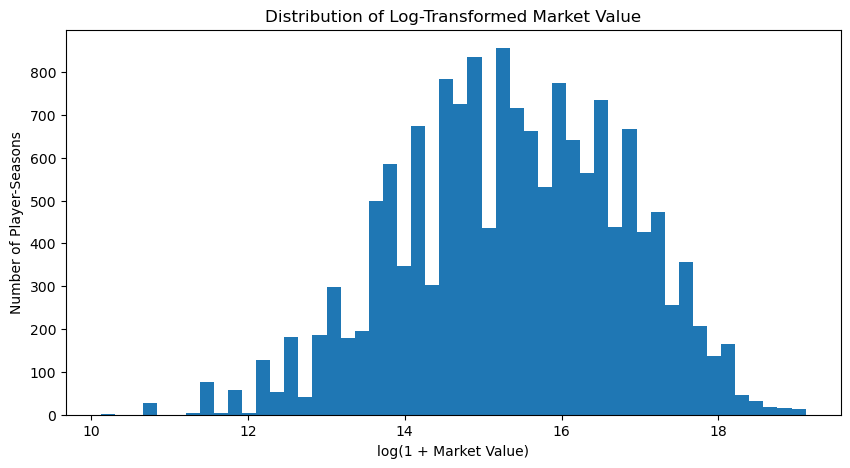

In [13]:
# Modified target variable distribution
plt.figure(figsize=(10, 5))

plt.hist(df["log_target_market_value"], bins=50)

plt.title("Distribution of Log-Transformed Market Value")
plt.xlabel("log(1 + Market Value)")
plt.ylabel("Number of Player-Seasons")

plt.show()

In [14]:
# Calculate modified skew
df["log_target_market_value"].skew()

np.float64(-0.20007690288334537)

In [15]:
# Compare
pd.DataFrame({
    "Target": ["Raw market value", "Log market value"],
    "Skewness": [
        df[target].skew(),
        df["log_target_market_value"].skew()
    ]
})

,Target,Skewness
0,Raw market value,3.649504
1,Log market value,-0.200077


A `log(1 + market value)` transformation was applied to the target variable. The transformation compresses very large market values more strongly than smaller values, reducing the influence of the most expensive players while preserving the ordering and relative differences between observations.

After applying the transformation, skewness decreased from 3.65 to -0.20. The resulting distribution is considerably more symmetric, showing that the transformation successfully reduced the strong right skew present in the original target.

Based on this result, the log-transformed market value will be used as the initial modeling target. The model will therefore learn and generate predictions on the logarithmic scale, while the predictions will later be transformed back into euros so that the final results remain easy to interpret.

#### 4.4 Target by Season

In [16]:
# Inspects target variable distribution by season
target_by_season = (
    df.groupby("season")[target]
      .agg(["count", "median", "mean", "min", "max"])
)

target_by_season

,count,median,mean,min,max
season,,,,,
2020,2617,4000000.0,9.904031e+06,50000,160000000
2021,2485,4500000.0,1.033817e+07,50000,160000000
2022,2657,4500000.0,1.049909e+07,25000,180000000
2023,2650,4500000.0,1.120470e+07,50000,180000000
2024,2489,5000000.0,1.218000e+07,50000,200000000
2025,2459,6000000.0,1.345157e+07,50000,200000000


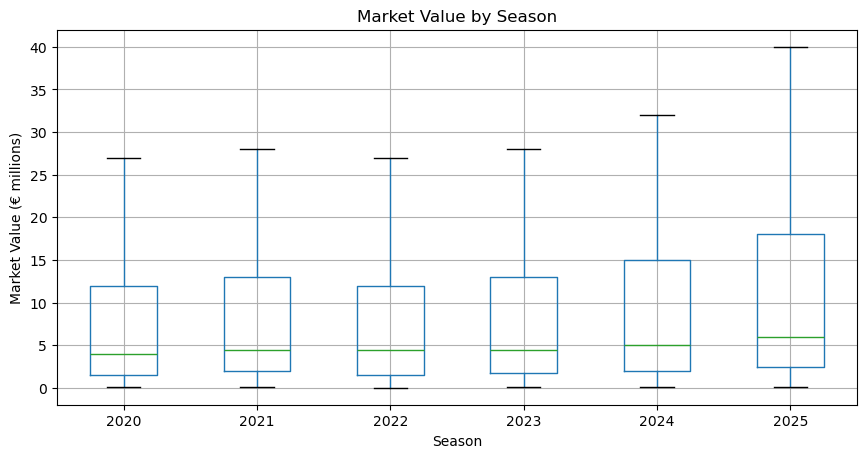

In [17]:
# Create boxplot
df_plot = df.copy()
df_plot["target_market_value_m"] = (
    df_plot["target_market_value_in_eur"] / 1_000_000
)

df_plot.boxplot(
    column="target_market_value_m",
    by="season",
    figsize=(10, 5),
    showfliers=False
)

plt.title("Market Value by Season")
plt.suptitle("")
plt.xlabel("Season")
plt.ylabel("Market Value (€ millions)")

plt.show()

Market value show a gradual upward trend across the observerd seasons.

The median increases from ~€4M in 2020 to ~€6M in 2025, while the mean rises from ~€9M to ~€13.5M over the same period.

The boxplot also shows a broader upper range in the most recent seasons, suggesting that the typical value player and the dispersion have increased over time.

This gives us more reasons to continue with the initial idea of respecting the cronological structure of the data, using earlier seasons for training and later seasons for validation and testing.

### 5. Feature Exploration

#### 5.1. Player Characteristics Features

The purpose here is to understand:
- how each feature is distributed,
- whether there are unusual values,
- and whether there appears to be a relationship with market value.

In [18]:
# Create market value in M euros for readability
df["target_market_value_m"] = (
    df["target_market_value_in_eur"] / 1_000_000
)

##### Age

In [19]:
# Describe feature
df['age_at_valuation'].describe()

count    15354.000000
mean        26.191742
std          4.544299
min         16.000000
25%         23.000000
50%         26.000000
75%         29.000000
max         43.000000
Name: age_at_valuation, dtype: float64

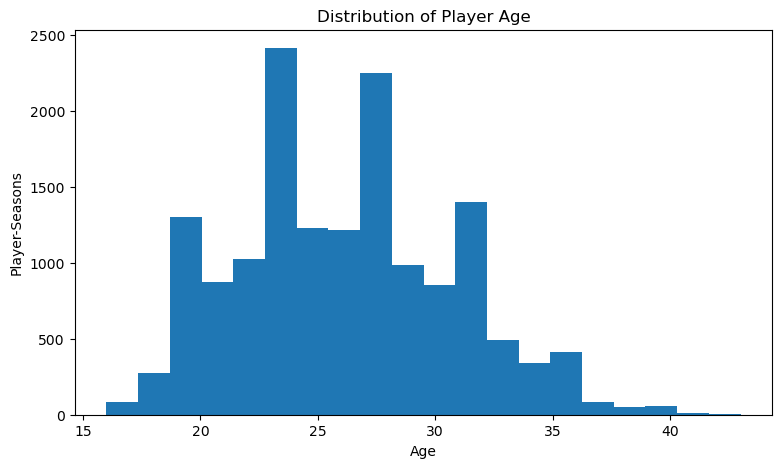

In [20]:
# Visualize feature
plt.figure(figsize=(9, 5))

plt.hist(df["age_at_valuation"].dropna(), bins=20)

plt.title("Distribution of Player Age")
plt.xlabel("Age")
plt.ylabel("Player-Seasons")

plt.show()

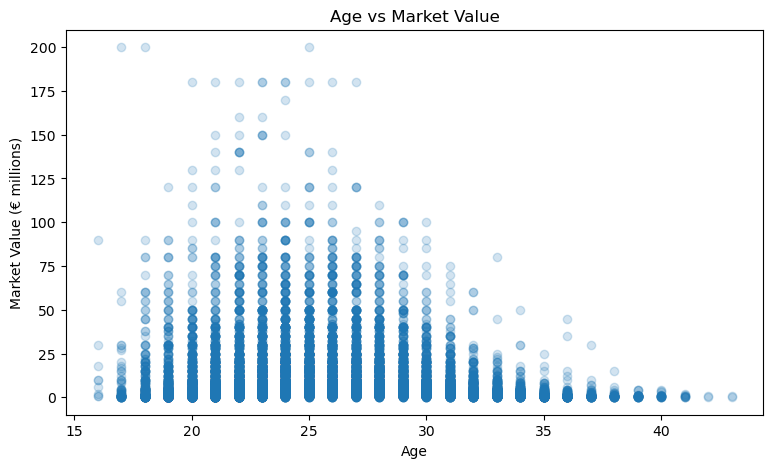

In [21]:
# Compare it agains market value (target)
plt.figure(figsize=(9, 5))

plt.scatter(
    df["age_at_valuation"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Age vs Market Value")
plt.xlabel("Age")
plt.ylabel("Market Value (€ millions)")

plt.show()

In [22]:
# Create tabular group by age view
age_value = (
    df.groupby("age_at_valuation")["target_market_value_m"]
      .agg(["count", "median", "mean"])
      .reset_index()
)

age_value

,age_at_valuation,count,median,mean
0,16.0,9,10.000,18.644444
1,17.0,72,1.300,9.016667
2,18.0,276,2.000,8.781069
3,19.0,571,2.500,8.276620
4,20.0,727,4.000,9.969120
5,21.0,874,6.000,12.661556
6,22.0,1025,7.000,14.277927
7,23.0,1191,7.500,14.821537
8,24.0,1222,8.000,15.787930
9,25.0,1226,8.000,15.466721


Player age shows a clear non-linear relationship with market value. Values generally increase from the late teenage years into the early and mid-20s, with the highest median values observed around ages 24–26. After this point, market values gradually decline as age increases.

The relationship is consistent with the typical career cycle of professional football players, where players tend to gain value as they develop and establish themselves, before valuations decrease later in their careers.

Results at the youngest and oldest ages should be interpreted carefully because these groups contain relatively few observations. For example, the unusually high average value at age 16 is based on only nine player-season observations. In this sense it is important to note that if a player manages to break into the top 5 leagues at 16 years old (three years before senior football age (19)), he is supposed to have a huge potential, reason why its value may be also higher.

From a modeling perspective, age is likely to be an important feature, but its relationship with market value is clearly non-linear.

##### Position ans Subposition

In [23]:
# Value count distribution
df["position"].value_counts()

position
Defender      5352
Midfield      4495
Attack        4305
Goalkeeper    1204
Missing          1
Name: count, dtype: int64

In [24]:
# Tabular view by position
position_value = (
    df.groupby("position")["target_market_value_m"]
      .agg(["count", "median", "mean"])
      .sort_values("median", ascending=False)
)

position_value

,count,median,mean
position,,,
Midfield,4495,5.5,12.353548
Attack,4305,5.0,13.035691
Defender,5352,4.5,9.884982
Goalkeeper,1204,3.0,6.676308
Missing,1,0.6,0.600000


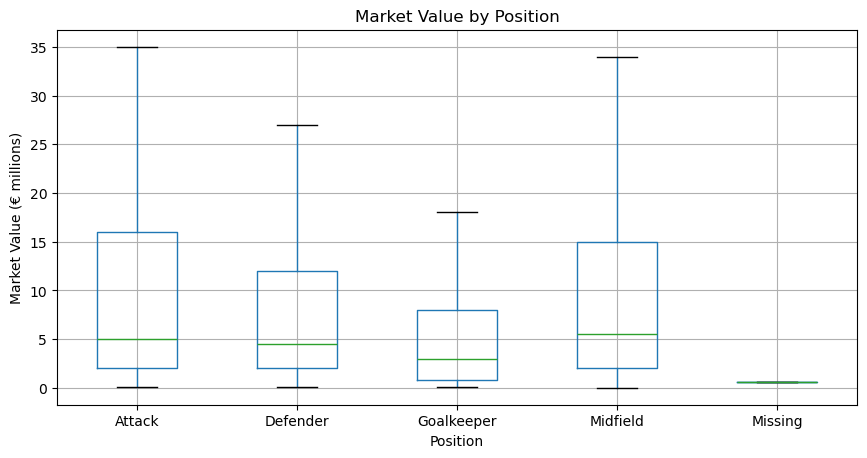

In [25]:
# Compare it against market value (target)
df.boxplot(
    column="target_market_value_m",
    by="position",
    figsize=(10, 5),
    showfliers=False
)

plt.title("Market Value by Position")
plt.suptitle("")
plt.xlabel("Position")
plt.ylabel("Market Value (€ millions)")

plt.show()

The distribution by position is consistent with the structure of a football team. There are considerably fewer goalkeepers than outfield players, since each team uses one goalkeeper but several defenders, midfielders and attackers.

Market value also differs clearly by position. Midfielders show the highest median market value at approximately ~€5.5M, followed by attackers at ~€5.0M, defenders at ~€4.5M and goalkeepers at ~€3.0M.

The mean values are higher than the medians for every position, which is consistent with the overall right-skewed market value distribution and the presence of a smaller number of very highly valued players.

From a modeling perspective, position is likely to be an important categorical feature because players in different roles are valued differently in the market. In football, scoring more goals than your opponent drives you to victory, so the attacking players tend to reach a higher value.

In [26]:
# Value count distribution
df["sub_position"].value_counts()

sub_position
Centre-Back           2877
Centre-Forward        2087
Central Midfield      1982
Right-Back            1330
Defensive Midfield    1270
Goalkeeper            1204
Left-Back             1145
Left Winger           1067
Right Winger          1019
Attacking Midfield    1016
Right Midfield         135
Second Striker         132
Left Midfield           92
Name: count, dtype: int64

In [27]:
# Tabular view by sub-position
sub_position_value = (
    df.groupby("sub_position")["target_market_value_m"]
      .agg(["count", "median", "mean"])
      .sort_values("median", ascending=False)
)

sub_position_value

,count,median,mean
sub_position,,,
Second Striker,132,7.25,13.893561
Attacking Midfield,1016,6.75,15.563041
Left Winger,1067,6.50,14.253327
Central Midfield,1982,5.50,11.902207
Centre-Back,2877,5.00,10.773922
Centre-Forward,2087,5.00,12.310062
Defensive Midfield,1270,5.00,11.508484
Right Winger,1019,5.00,13.135721
Left Midfield,92,4.25,6.944565


Sub-position provides a more detailed view of player roles than the analysis above. Centre-backs, centre-forwards and central midfielders are the most common sub-positions in the dataset, while more specialized roles such as second striker, left midfield and right midfield contain fewer observations.

Market value also varies across sub-positions. Among the larger groups, attacking midfielders and left wingers show some of the highest median and average market values. Second strikers show the highest median value overall, although this result should be interpreted carefully because the category contains less observations.

From a modeling perspective, sub-position appears useful because it captures differences that are hidden within the broader position categories. At the same time, categories with relatively few observations should be treated carefully to avoid drawing strong conclusions from small samples.

##### Preferred foot

In [28]:
# Value counts
df["foot"].value_counts(dropna=False)

foot
right    10815
left      4000
both       481
NaN         61
Name: count, dtype: int64

In [29]:
# Tabular view by foot preferred
foot_value = (
    df.groupby("foot", dropna=False)["target_market_value_m"]
      .agg(["count", "median", "mean"])
)

foot_value

,count,median,mean
foot,,,
both,481,4.00,11.620322
left,4000,5.00,11.678194
right,10815,5.00,11.115980
NaN,61,0.25,1.142213


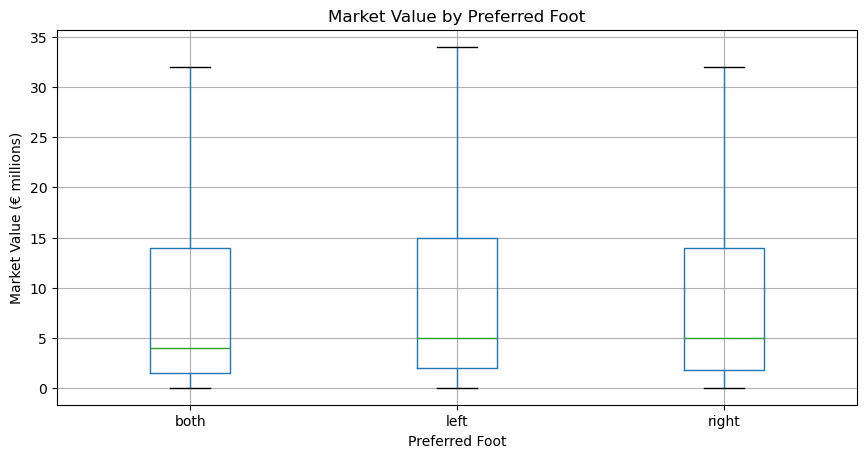

In [63]:
# Compare it against market value (target)
df.boxplot(
    column="target_market_value_m",
    by="foot",
    figsize=(10, 5),
    showfliers=False
)

plt.title("Market Value by Preferred Foot")
plt.suptitle("")
plt.xlabel("Preferred Foot")
plt.ylabel("Market Value (€ millions)")

plt.show()

Right-footed players are clearly the most common group in the dataset, with 10,815 player-season observations, compared with 4,000 left-footed players and 481 players using both feet.

Market values are broadly similar across the main foot categories. Left and right-footed players both show a median market value of ~€5M, while left-footed players have a slightly higher average market value.

Players recorded as using both feet show a lower median value of approximately €4M, although this group is considerably smaller.

From a modeling perspective, preferred foot may provide some useful information, but the differences are relatively small compared with features such as age, position or performance.

##### Height

In [31]:
# Describe variable
df["height_in_cm"].describe()

count    15321.00000
mean       182.93845
std          6.63889
min        162.00000
25%        178.00000
50%        183.00000
75%        188.00000
max        206.00000
Name: height_in_cm, dtype: float64

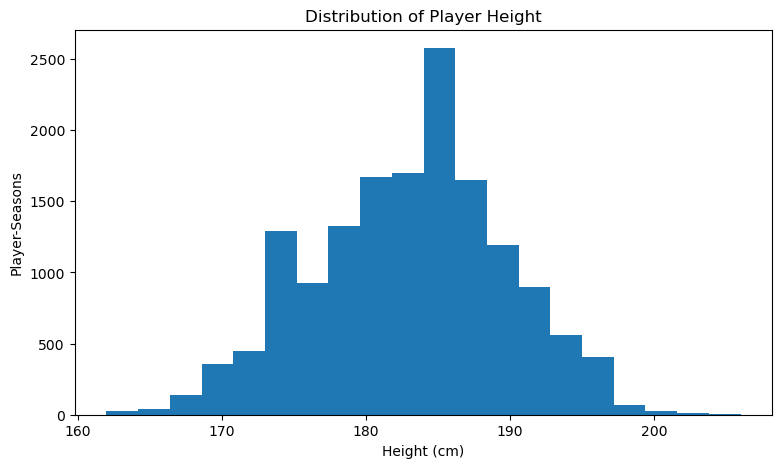

In [32]:
# Distribution histogram
plt.figure(figsize=(9, 5))

plt.hist(df["height_in_cm"].dropna(), bins=20)

plt.title("Distribution of Player Height")
plt.xlabel("Height (cm)")
plt.ylabel("Player-Seasons")

plt.show()

In [33]:
# Correlation with target (log version to avoid skewness)
df[
    ["height_in_cm", "log_target_market_value"]
].corr()

,height_in_cm,log_target_market_value
height_in_cm,1.000000,-0.022903
log_target_market_value,-0.022903,1.000000


Player height follows a relatively regular distribution, with an average of approximately 183 cm and most observations concentrated between 178 cm and 188 cm.

The correlation between height and the log-transformed market value is approximately -0.02, indicating almost no overall linear relationship between the two variables.

This suggests that height alone is unlikely to be an important predictor of market value across all players. However, its relevance may depend on position or sub-position, since height can be more important for some roles than for others.

For this reason, height will be retained for now, but its contribution should be evaluated together with positional information during modeling.

#### 5.2. Performance Features

##### Played Games and Time

In [34]:
# Describe features
played_time_features = [
    "total_games_played_season",
    "total_minutes_played"
]

df[played_time_features].describe()

,total_games_played_season,total_minutes_played
count,15357.000000,15357.000000
mean,21.004493,1363.274272
std,11.048499,960.518094
min,1.000000,1.000000
25%,12.000000,496.000000
50%,23.000000,1305.000000
75%,30.000000,2144.000000
max,39.000000,3420.000000


In [35]:
# Find correlation between played_time_features and with target variable
df[
    played_time_features + ["log_target_market_value"]
].corr()

,total_games_played_season,total_minutes_played,log_target_market_value
total_games_played_season,1.000000,0.904630,0.549602
total_minutes_played,0.904630,1.000000,0.526226
log_target_market_value,0.549602,0.526226,1.000000


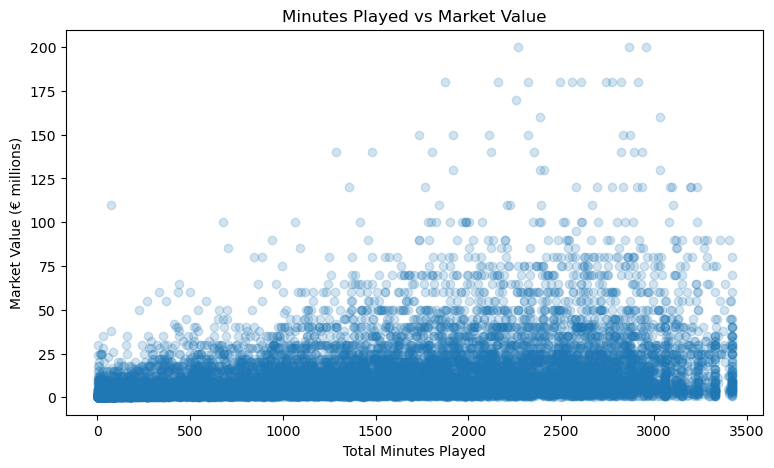

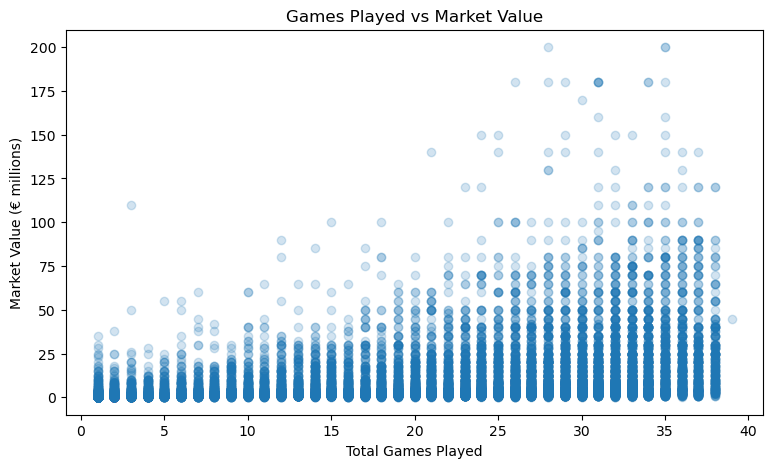

In [36]:
# Visualize the relation

# Minutes played
plt.figure(figsize=(9, 5))
plt.scatter(
    df["total_minutes_played"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Minutes Played vs Market Value")
plt.xlabel("Total Minutes Played")
plt.ylabel("Market Value (€ millions)")
plt.show()

# Games played
plt.figure(figsize=(9, 5))
plt.scatter(
    df["total_games_played_season"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Games Played vs Market Value")
plt.xlabel("Total Games Played")
plt.ylabel("Market Value (€ millions)")
plt.show()


Playing time shows a clear positive relationship with market value. Both total games played and total minutes played have moderate positive correlations with the log-transformed target variable, at ~0.55 and ~0.53 respectively. The scatterplots also show that players with greater season involvement tend to reach higher market valuations.

This does not seem to be casual, better performing players tend to play more, and for that reason, reach higher market values. Needless to say, that a player that is not participating usually would have a significant lower value than one that is able to play all minutes in all games of a season.

Total games and total minutes are themselves highly correlated (0.90), which is expected since players who appear in more matches normally accumulate more minutes. The two features therefore contain substantial overlapping information. Both will be retained during the exploratory stage, while their redundancy will be considered later during feature selection and model evaluation.

##### Attacking Performance

In [37]:
# Describe features
attacking_features = [
    "total_goals",
    "goals_per_90_min",
    "total_assists",
    "assists_per_90_min",
    "goal_contributions_per_90_min"
]

df[attacking_features].describe()


,total_goals,goals_per_90_min,total_assists,assists_per_90_min,goal_contributions_per_90_min
count,15357.000000,9588.000000,15357.000000,9588.000000,9588.000000
mean,1.885394,0.128079,1.466693,0.099654,0.227736
std,3.317747,0.165582,2.189008,0.108157,0.232685
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.055000
50%,1.000000,0.068000,1.000000,0.072000,0.155000
75%,2.000000,0.185000,2.000000,0.154000,0.344000
max,41.000000,1.498000,21.000000,0.829000,1.944000


In [38]:
# Find correlation with target variable
df[
    attacking_features + ["log_target_market_value"]
].corr()["log_target_market_value"].sort_values(ascending=False)

log_target_market_value          1.000000
total_assists                    0.438834
total_goals                      0.417222
goal_contributions_per_90_min    0.364844
goals_per_90_min                 0.317254
assists_per_90_min               0.299187
Name: log_target_market_value, dtype: float64

In [39]:
# Break down by position
positions = ["Attack", "Midfield", "Defender", "Goalkeeper"]

attacking_features = [
    "total_goals",
    "goals_per_90_min",
    "total_assists",
    "assists_per_90_min",
    "goal_contributions_per_90_min"
]

attacking_by_position = pd.DataFrame({
    position: (
        df[df["position"] == position]
        [attacking_features + ["log_target_market_value"]]
        .corr()["log_target_market_value"]
        .drop("log_target_market_value")
    )
    for position in positions
})

attacking_by_position

,Attack,Midfield,Defender,Goalkeeper
total_goals,0.575312,0.465404,0.345860,0.069054
goals_per_90_min,0.407265,0.321294,0.200023,0.073514
total_assists,0.550140,0.460861,0.302197,0.151646
assists_per_90_min,0.356248,0.287219,0.144521,0.059481
goal_contributions_per_90_min,0.512551,0.362887,0.215922,0.069908


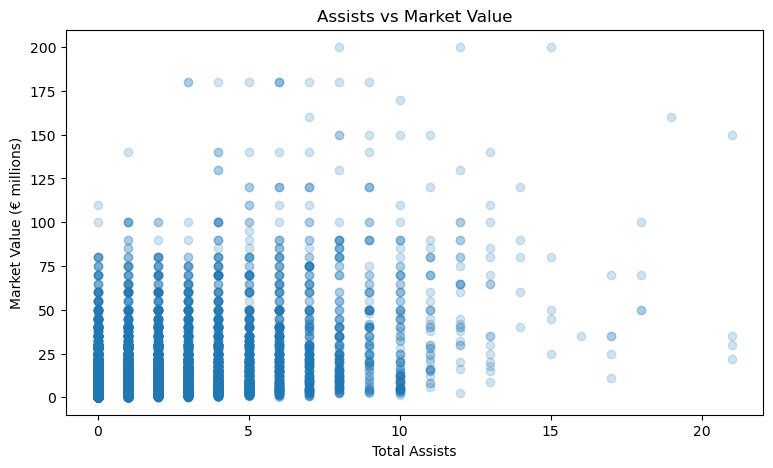

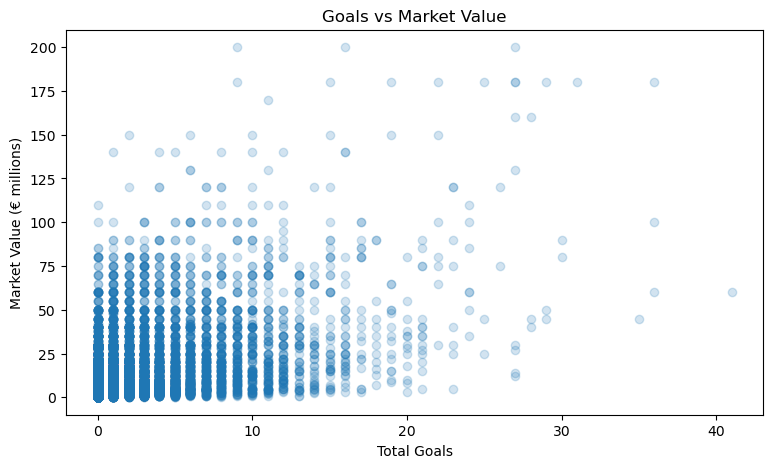

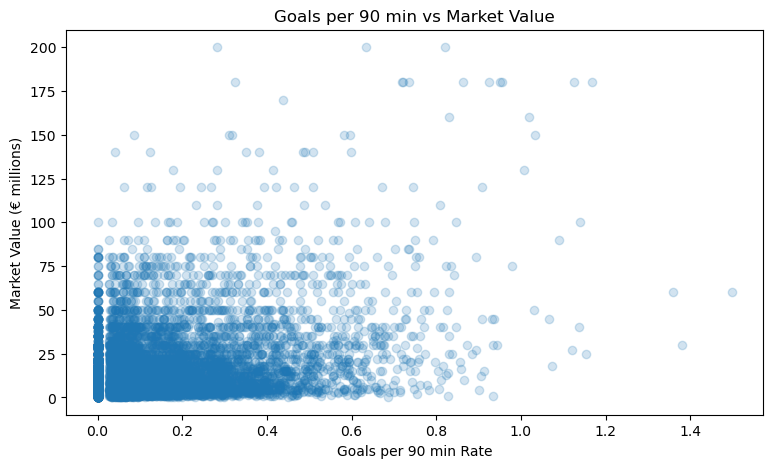

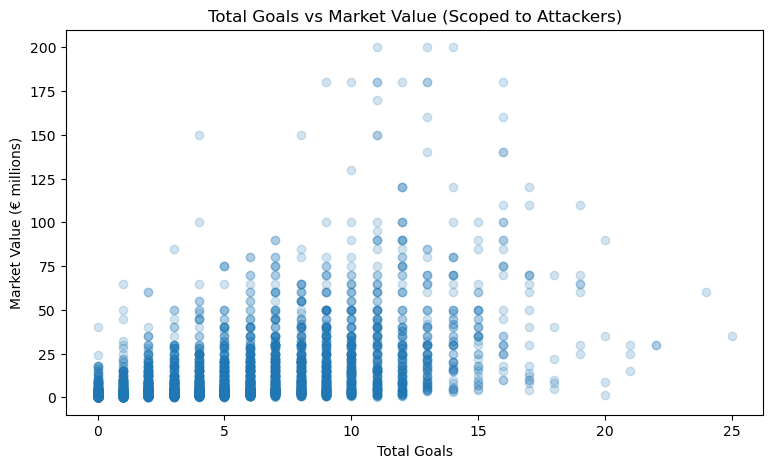

In [40]:
# Visualize the main findings

# total_assists
plt.figure(figsize=(9, 5))
plt.scatter(
    df["total_assists"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Assists vs Market Value")
plt.xlabel("Total Assists")
plt.ylabel("Market Value (€ millions)")
plt.show()

# total_goals
plt.figure(figsize=(9, 5))
plt.scatter(
    df["total_goals"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Goals vs Market Value")
plt.xlabel("Total Goals")
plt.ylabel("Market Value (€ millions)")
plt.show()

# goals_per_90_min
plt.figure(figsize=(9, 5))
plt.scatter(
    df["goals_per_90_min"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Goals per 90 min vs Market Value")
plt.xlabel("Goals per 90 min Rate")
plt.ylabel("Market Value (€ millions)")
plt.show()

# total_goals scoped to attacking players
attackers = df[df["position"] == 'Attack']

plt.figure(figsize=(9, 5))
plt.scatter(
    attackers["total_clean_sheets"],
    attackers["target_market_value_m"],
    alpha=0.2
)

plt.title("Total Goals vs Market Value (Scoped to Attackers)")
plt.xlabel("Total Goals")
plt.ylabel("Market Value (€ millions)")
plt.show()

Initially, the per-90 attacking features were affected by very small samples, where players with limited minutes could show unrealistically high rates. After applying a minimum threshold of 900 minutes, these features became more stable and their relationship with market value improved.

Total goals and assists still show slightly stronger correlations with the target than the per-90 metrics, which makes sense because they capture both performance and sustained participation over the season.

The position breakdown adds an important insight: attacking metrics are much more strongly related to market value for attackers and midfielders than for defenders, while they are almost irrelevant for goalkeepers. This confirms that the value of a performance feature depends heavily on the player’s role.

For modeling, both positional and performance features will therefore be retained so the model can learn these interactions automatically rather than applying the same importance to every metric across all players.

##### Defensive Features

In [41]:
# Describe variables
defensive_features = [
    "total_clean_sheets",
    "clean_sheet_rate",
    "total_yellow_cards",
    "yellow_cards_per_90_min",
    "total_red_cards",
    "red_cards_per_90_min"
]

df[defensive_features].describe()

,total_clean_sheets,clean_sheet_rate,total_yellow_cards,yellow_cards_per_90_min,total_red_cards,red_cards_per_90_min
count,15357.000000,9588.000000,15357.000000,9588.000000,15357.000000,9588.000000
mean,5.435306,0.260200,2.784789,0.185664,0.062317,0.004189
std,4.094172,0.115389,2.689276,0.124305,0.257900,0.015400
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.182000,1.000000,0.092107,0.000000,0.000000
50%,5.000000,0.250000,2.000000,0.170100,0.000000,0.000000
75%,8.000000,0.333000,4.000000,0.259550,0.000000,0.000000
max,26.000000,0.733000,17.000000,0.905330,3.000000,0.188480


In [42]:
# Find correlation with target variable
df[
    defensive_features + ["log_target_market_value"]
].corr()["log_target_market_value"].sort_values(ascending=False)

log_target_market_value    1.000000
total_clean_sheets         0.572253
clean_sheet_rate           0.366409
total_yellow_cards         0.315621
total_red_cards            0.040586
red_cards_per_90_min      -0.063872
yellow_cards_per_90_min   -0.094954
Name: log_target_market_value, dtype: float64

In [43]:
# Break down by position

defensive_by_position = pd.DataFrame({
    position: (
        df[df["position"] == position]
        [defensive_features + ["log_target_market_value"]]
        .corr()["log_target_market_value"]
        .drop("log_target_market_value")
    )
    for position in positions
}).T

defensive_by_position

,total_clean_sheets,clean_sheet_rate,total_yellow_cards,yellow_cards_per_90_min,total_red_cards,red_cards_per_90_min
Attack,0.589381,0.388377,0.316605,-0.159746,0.039900,-0.057881
Midfield,0.568933,0.374156,0.337781,-0.129494,0.043496,-0.070604
Defender,0.531660,0.363455,0.295023,-0.096409,0.028361,-0.066520
Goalkeeper,0.644769,0.361856,0.366452,-0.033246,0.109608,0.023806


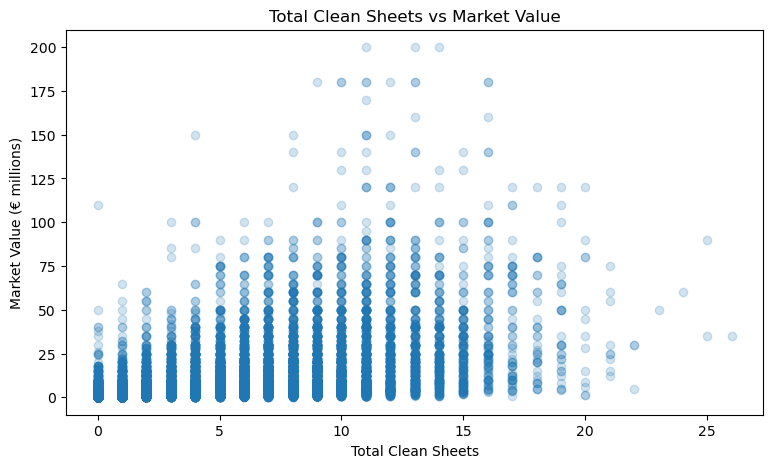

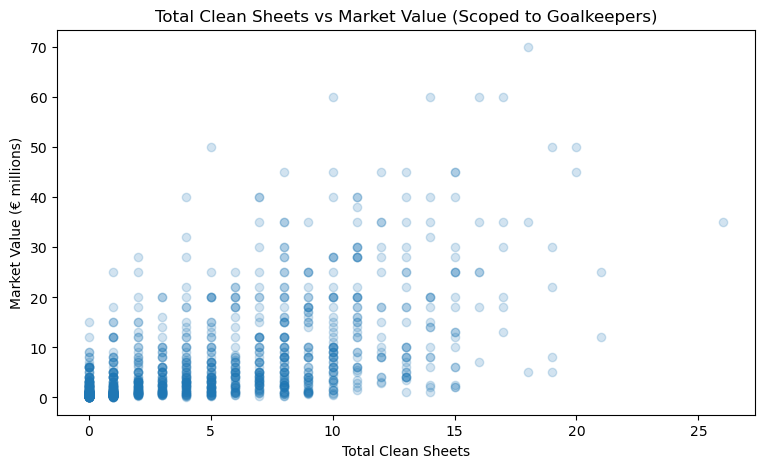

In [44]:
# Visualize the main findings

# total_clean_sheets
plt.figure(figsize=(9, 5))
plt.scatter(
    df["total_clean_sheets"],
    df["target_market_value_m"],
    alpha=0.2
)

plt.title("Total Clean Sheets vs Market Value")
plt.xlabel("Total Clean Sheets")
plt.ylabel("Market Value (€ millions)")
plt.show()

# total_clean_sheets for goalkeeper position
goalkeepers = df[df["position"] == 'Goalkeeper']

plt.figure(figsize=(9, 5))
plt.scatter(
    goalkeepers["total_clean_sheets"],
    goalkeepers["target_market_value_m"],
    alpha=0.2
)

plt.title("Total Clean Sheets vs Market Value (Scoped to Goalkeepers)")
plt.xlabel("Total Clean Sheets")
plt.ylabel("Market Value (€ millions)")
plt.show()

Clean sheets show the strongest relationship with market value among the defensive features. total_clean_sheets has a strong positive relationship across all positions and is strongest for goalkeepers at approximately 0.64.

After applying the 900-minute minimum threshold, clean_sheet_rate also became more meaningful, reaching correlations of roughly 0.36–0.39 across positions. This reduced the distortion caused by players with very limited playing time.

Clean-sheet metrics still likely capture a mixture of individual performance, team strength and player participation, so they should not be interpreted as pure defensive ability.

Yellow-card totals show a weaker positive relationship with market value, while card rates and red-card features provide little consistent signal.

#### 5.3. Club/Competition Related Features

In [45]:
# Describe variables
club_features = [
    "club_goals_scored",
    "club_goals_conceded",
    "wins",
    "draws",
    "losses",
    "club_games_played",
    "points",
    "avg_points_per_game"
]

df[club_features].describe()

,club_goals_scored,club_goals_conceded,wins,draws,losses,club_games_played,points,avg_points_per_game
count,15357.000000,15357.000000,15357.000000,15357.000000,15357.000000,15357.000000,15357.000000,15357.000000
mean,51.212086,52.374357,13.488442,9.402097,13.996484,36.887022,49.867422,1.352367
std,16.272827,13.037942,6.035911,2.860798,5.464488,1.792596,17.155719,0.460353
min,20.000000,20.000000,2.000000,1.000000,0.000000,34.000000,12.000000,0.320000
25%,40.000000,44.000000,9.000000,7.000000,10.000000,34.000000,38.000000,1.030000
50%,49.000000,52.000000,12.000000,9.000000,14.000000,38.000000,46.000000,1.260000
75%,61.000000,60.000000,18.000000,11.000000,18.000000,38.000000,62.000000,1.680000
max,122.000000,104.000000,31.000000,19.000000,30.000000,38.000000,95.000000,2.650000


In [46]:
# Find correlation with target variable
df[
    club_features + ["log_target_market_value"]
].corr()["log_target_market_value"].sort_values(ascending=False)

log_target_market_value    1.000000
wins                       0.451713
points                     0.451564
avg_points_per_game        0.445641
club_goals_scored          0.444365
club_games_played          0.069802
draws                     -0.151218
club_goals_conceded       -0.324248
losses                    -0.396885
Name: log_target_market_value, dtype: float64

In [47]:
# Correlation between features
club_feature_corr = df[club_features].corr().round(2)
club_feature_corr

,club_goals_scored,club_goals_conceded,wins,draws,losses,club_games_played,points,avg_points_per_game
club_goals_scored,1.00,-0.52,0.87,-0.34,-0.79,-0.01,0.87,0.88
club_goals_conceded,-0.52,1.00,-0.76,0.03,0.83,0.02,-0.80,-0.81
wins,0.87,-0.76,1.00,-0.40,-0.87,0.08,0.99,0.98
draws,-0.34,0.03,-0.40,1.00,-0.01,0.22,-0.26,-0.29
losses,-0.79,0.83,-0.87,-0.01,1.00,0.12,-0.92,-0.94
club_games_played,-0.01,0.02,0.08,0.22,0.12,1.00,0.12,-0.02
points,0.87,-0.80,0.99,-0.26,-0.92,0.12,1.00,0.99
avg_points_per_game,0.88,-0.81,0.98,-0.29,-0.94,-0.02,0.99,1.00


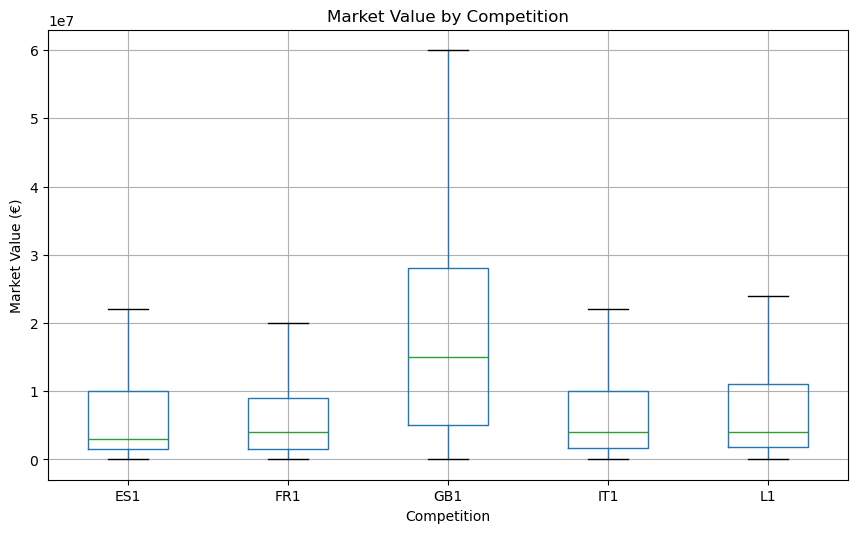

In [48]:
# Distribution by competition
df.boxplot(
    column="target_market_value_in_eur",
    by="competition_id",
    showfliers=False,
    figsize=(10, 6)
)

plt.title("Market Value by Competition")
plt.suptitle("")
plt.xlabel("Competition")
plt.ylabel("Market Value (€)")
plt.show()

In [49]:
# Inspect primary_club_id feature
    # Tabular view by club
foot_value = (
    df.groupby("primary_club_id", dropna=False)["target_market_value_m"]
      .agg(["count", "median", "mean"])
)

display(foot_value)

,count,median,mean
primary_club_id,,,
3,126,3.00,4.182937
5,161,15.00,18.994099
10,51,1.80,2.274510
11,137,32.00,39.361314
12,159,9.00,13.377358
...,...,...,...
8970,33,1.80,3.159091
10004,28,3.75,5.442857
12321,103,3.00,7.111165


Club performance shows a meaningful relationship with player market value. Stronger club indicators such as avg_points_per_game, points, wins, and club_goals_scored all show correlations of approximately 0.44–0.45 with the log-transformed target. In contrast, losses and club_goals_conceded have negative relationships of approximately -0.40 and -0.32.

Several club features are highly redundant. points, wins, and avg_points_per_game correlate at around 0.98–0.99 with each other, meaning they largely represent the same underlying concept of club performance. This will be considered during feature selection rather than keeping all of them automatically.

Competition also shows a clear difference in market-value distributions. Premier League (GB1) players have substantially higher median and upper-range valuations than players in the other four leagues, suggesting that competition provides relevant market context.

Overall, club strength and competition appear useful contextual features, although they should be interpreted as associations rather than direct causes of player value.

#### 5.4. Historical Market Value Feature

In [50]:
# Describe the variables
historical_value_features = [
    "previous_market_value_in_eur",
    "days_since_previous_valuation"
]

df[historical_value_features].describe()

,previous_market_value_in_eur,days_since_previous_valuation
count,1.527500e+04,15275.000000
mean,1.139101e+07,143.344746
std,1.671418e+07,53.177547
min,2.500000e+04,31.000000
25%,2.000000e+06,84.000000
50%,5.000000e+06,160.000000
75%,1.500000e+07,173.000000
max,2.000000e+08,743.000000


In [51]:
# Check missingness
df[historical_value_features].isna().sum()

previous_market_value_in_eur     82
days_since_previous_valuation    82
dtype: int64

In [52]:
# Create log version of previous_market_value_in_eur to allow comparison
df["log_previous_market_value"] = np.log1p(
    df["previous_market_value_in_eur"]
)

In [53]:
# Find correlation with target variable

historical_value_features_updated = [
    "previous_market_value_in_eur",
    "log_previous_market_value",
    "days_since_previous_valuation",
]

df[
    historical_value_features_updated + ["log_target_market_value"]
].corr()["log_target_market_value"].sort_values(ascending=False)


log_target_market_value          1.000000
log_previous_market_value        0.980397
previous_market_value_in_eur     0.746999
days_since_previous_valuation   -0.211391
Name: log_target_market_value, dtype: float64

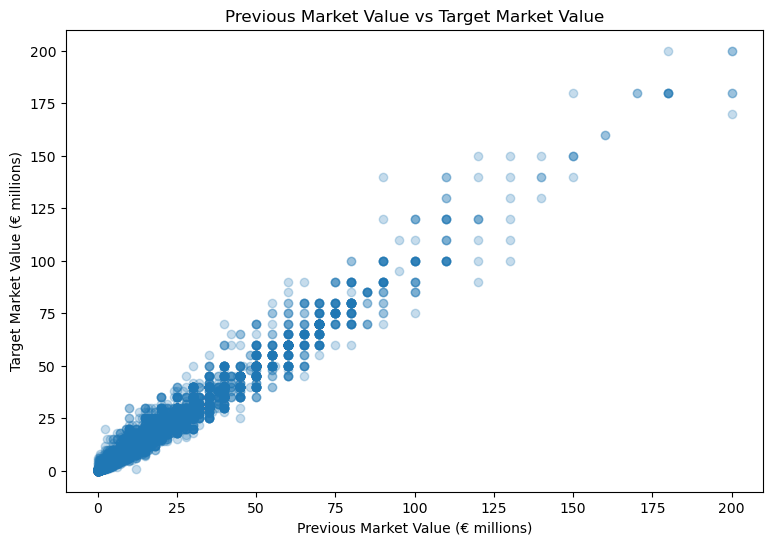

In [54]:
# Plot main findings
plt.figure(figsize=(9, 6))

plt.scatter(
    df["previous_market_value_in_eur"] / 1_000_000,
    df["target_market_value_in_eur"] / 1_000_000,
    alpha=0.25
)

plt.xlabel("Previous Market Value (€ millions)")
plt.ylabel("Target Market Value (€ millions)")
plt.title("Previous Market Value vs Target Market Value")

plt.show()

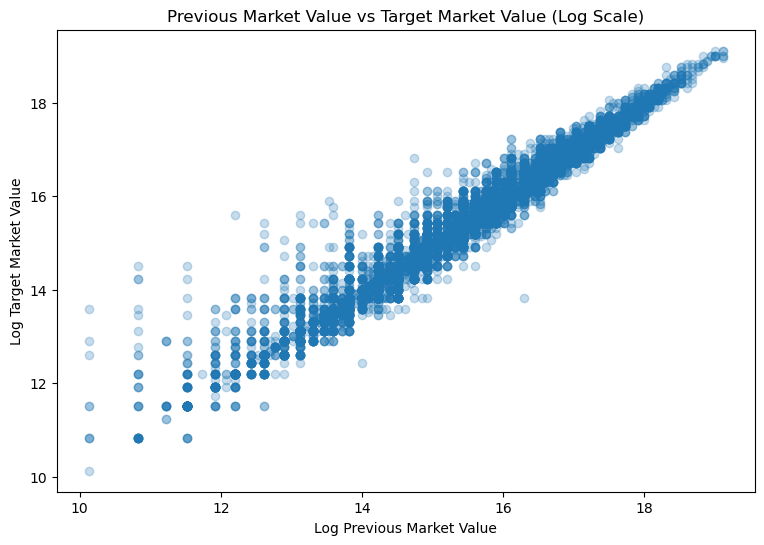

In [55]:
# Plot main findings
plt.figure(figsize=(9, 6))

plt.scatter(
    df["log_previous_market_value"],
    df["log_target_market_value"],
    alpha=0.25
)

plt.xlabel("Log Previous Market Value")
plt.ylabel("Log Target Market Value")
plt.title("Previous Market Value vs Target Market Value (Log Scale)")

plt.show()

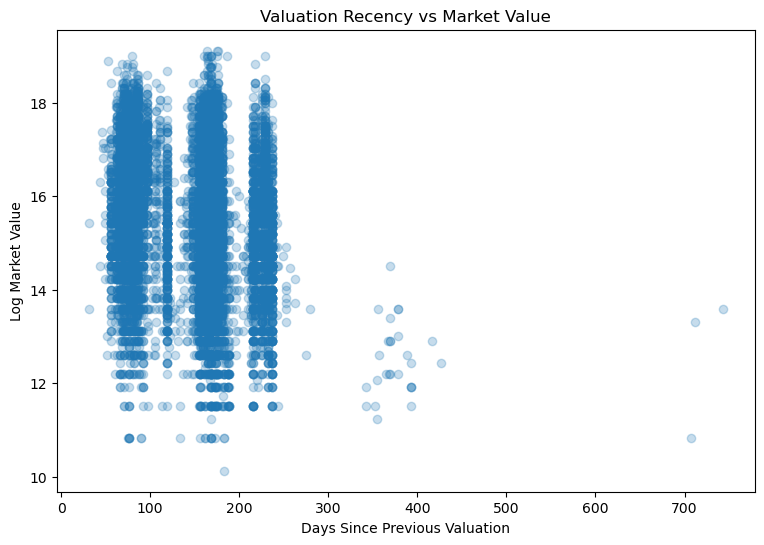

In [56]:
# Plot main findings
plt.figure(figsize=(9, 6))

plt.scatter(
    df["days_since_previous_valuation"],
    df["log_target_market_value"],
    alpha=0.25
)

plt.xlabel("Days Since Previous Valuation")
plt.ylabel("Log Market Value")
plt.title("Valuation Recency vs Market Value")

plt.show()

Historical market value is by far the strongest feature identified so far. After log transformation, previous market value shows a correlation of approximately 0.98 with the log-transformed target, indicating very strong persistence in player valuations between consecutive valuation periods.

The raw scatterplot also shows a clear near-linear relationship, while the log-scale plot makes this relationship even more evident across the full value range. Feature days_since_previous_valuation has a weaker negative relationship with the target at approximately -0.21, suggesting that older historical valuations contain somewhat less information about the current value.

Historical valuation data is available for 15,275 of 15,357 observations, leaving only 82 missing cases.

Because previous market value is so dominant, the modeling stage should compare performance with and without this feature. This will show how much predictive information the season-performance and contextual features contribute beyond simply carrying forward the player's previous valuation.

This result should also be interpreted with care, as it is not surprising that market values remain relatively stable from one season to the next. Player value is generally built or lost progressively over time rather than changing completely within a single season, although younger players can experience much faster increases or decreases. Therefore, the very high correlation partly reflects the natural persistence of market valuations and should not be interpreted as evidence that previous market value alone explains the factors driving player value.

#### 5.5. Transfer Features

In [57]:
# Describe variables
transfer_features = [
    "total_previous_transfers",
    "transfers_during_season",
    "has_previous_transfer",
    "days_since_last_transfer"
]

df[transfer_features].describe()

,total_previous_transfers,transfers_during_season,has_previous_transfer,days_since_last_transfer
count,15357.000000,15357.000000,15357.000000,13905.000000
mean,6.917236,0.269779,0.905450,810.187558
std,4.297859,0.542016,0.292602,795.215960
min,0.000000,0.000000,0.000000,1.000000
25%,4.000000,0.000000,1.000000,298.000000
50%,6.000000,0.000000,1.000000,518.000000
75%,9.000000,0.000000,1.000000,1066.000000
max,28.000000,5.000000,1.000000,5847.000000


In [58]:
# Check for missing values
df[transfer_features].isna().sum()

total_previous_transfers       0
transfers_during_season        0
has_previous_transfer          0
days_since_last_transfer    1452
dtype: int64

In [59]:
# Find correlation with target variable
df[
    transfer_features + ["log_target_market_value"]
].corr()["log_target_market_value"].sort_values(ascending=False)

log_target_market_value     1.000000
has_previous_transfer       0.318314
total_previous_transfers    0.106958
days_since_last_transfer    0.077298
transfers_during_season    -0.032538
Name: log_target_market_value, dtype: float64

In [60]:
# Compare previosly transfered players with non-transfered ones
previous_transfer_summary = (
    df.groupby("has_previous_transfer")["target_market_value_in_eur"]
    .agg(["count", "median", "mean"])
)

previous_transfer_summary[["median", "mean"]] /= 1_000_000

previous_transfer_summary

,count,median,mean
has_previous_transfer,,,
0,1452,1.2,2.247211
1,13905,6.0,12.177504


In [61]:
# Check transfers during season
season_transfer_summary = (
    df.groupby("transfers_during_season")["target_market_value_in_eur"]
    .agg(["count", "median", "mean"])
)

season_transfer_summary[["median", "mean"]] /= 1_000_000

season_transfer_summary

,count,median,mean
transfers_during_season,,,
0,11800,5.00,12.112017
1,3112,4.50,8.511809
2,317,4.00,7.651735
3,118,4.75,5.948305
4,7,3.50,5.657143
5,3,4.00,4.500000


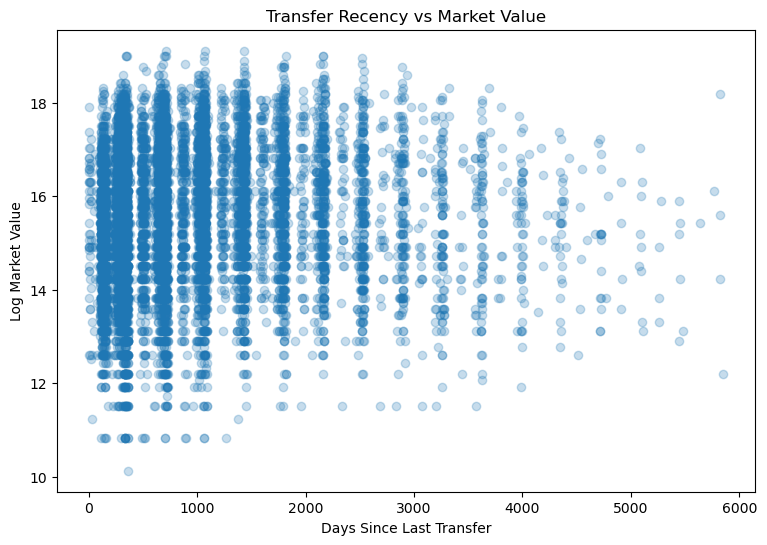

In [62]:
# Plot main findings

plt.figure(figsize=(9, 6))

plt.scatter(
    df["days_since_last_transfer"],
    df["log_target_market_value"],
    alpha=0.25
)

plt.xlabel("Days Since Last Transfer")
plt.ylabel("Log Market Value")
plt.title("Transfer Recency vs Market Value")

plt.show()

Transfer history shows some relationship with market value, although much weaker than historical valuation or performance features. has_previous_transfer has the strongest correlation with the target at approximately 0.32. Players with previous transfers also have substantially higher market values, with a median of around €6.0M compared with €1.2M for players without a previous transfer.

This should be interpreted carefully, as having a previous transfer may also reflect career stage, professional experience, or greater career mobility, rather than transfers directly increasing market value.

total_previous_transfers shows only a weak positive relationship (0.11), while days_since_last_transfer is close to zero (0.08). transfers_during_season also shows almost no linear relationship with the target (-0.03), despite players with multiple in-season transfers tending to have lower average values.

The transfer features will therefore be retained for modeling, but they appear to provide secondary contextual information rather than being major drivers on their own.